In [1]:
!pip install torch torchvision matplotlib pillow numpy

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

from PIL import Image
from torchvision import transforms
from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
model = torch.hub.load(
    'mateuszbuda/brain-segmentation-pytorch',
    'unet',
    in_channels=3,
    out_channels=1,
    init_features=32,
    pretrained=True
)

model.eval()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("U-Net Model Loaded Successfully")
print("Device:", device)

U-Net Model Loaded Successfully
Device: cuda


Using cache found in /root/.cache/torch/hub/mateuszbuda_brain-segmentation-pytorch_master


In [5]:
import urllib.request
from PIL import Image

url = "https://github.com/mateuszbuda/brain-segmentation-pytorch/raw/master/assets/TCGA_CS_4944.png"

urllib.request.urlretrieve(url, "brain_mri.png")

image = Image.open("brain_mri.png").convert("RGB")

print("MRI Image Downloaded Successfully")
print("Image Size:", image.size)

MRI Image Downloaded Successfully
Image Size: (256, 256)


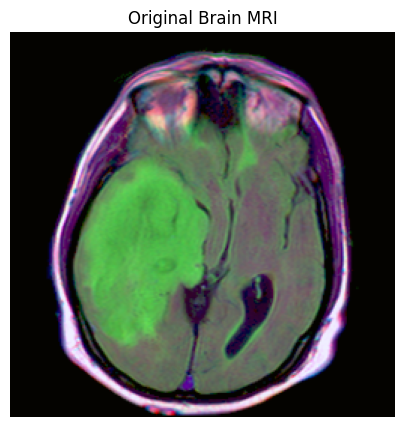

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,5))
plt.imshow(image)
plt.title("Original Brain MRI")
plt.axis("off")
plt.show()

In [15]:
import numpy as np
from torchvision import transforms

image_array = np.asarray(image).astype(np.float32)

# Calculate normalized channel statistics
mean = image_array.mean(axis=(0, 1)) / 255.0
std = image_array.std(axis=(0, 1)) / 255.0

std[std == 0] = 1.0

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

input_tensor = preprocess(image)
input_batch = input_tensor.unsqueeze(0).to(device)

print("Preprocessing Corrected")
print("Input Shape:", input_batch.shape)
print("Input Min:", input_batch.min().item())
print("Input Max:", input_batch.max().item())

Preprocessing Corrected
Input Shape: torch.Size([1, 3, 256, 256])
Input Min: -0.9823223352432251
Input Max: 3.3477771282196045


In [16]:
with torch.no_grad():
    output = model(input_batch)

probability_map = output[0, 0].cpu().numpy()

print("Segmentation Completed")
print("Output Shape:", probability_map.shape)
print("Mask Values:", np.unique(segmentation_mask))

Segmentation Completed
Output Shape: (256, 256)
Mask Values: [0]


In [17]:
print("Probability minimum:", probability_map.min())
print("Probability maximum:", probability_map.max())
print("Probability mean:", probability_map.mean())

print("Input mean:", input_batch.mean().item())
print("Input standard deviation:", input_batch.std().item())

print("Model output shape:", output.shape)

Probability minimum: 2.0408243e-06
Probability maximum: 1.0
Probability mean: 0.10729081
Input mean: 4.03573130469681e-09
Input standard deviation: 0.9999551177024841
Model output shape: torch.Size([1, 1, 256, 256])


In [18]:
threshold = 0.5

segmentation_mask = (
    probability_map >= threshold
).astype(np.uint8)

print("Segmentation Completed")
print("Mask Values:", np.unique(segmentation_mask))
print("Foreground Pixels:", segmentation_mask.sum())

Segmentation Completed
Mask Values: [0 1]
Foreground Pixels: 7033


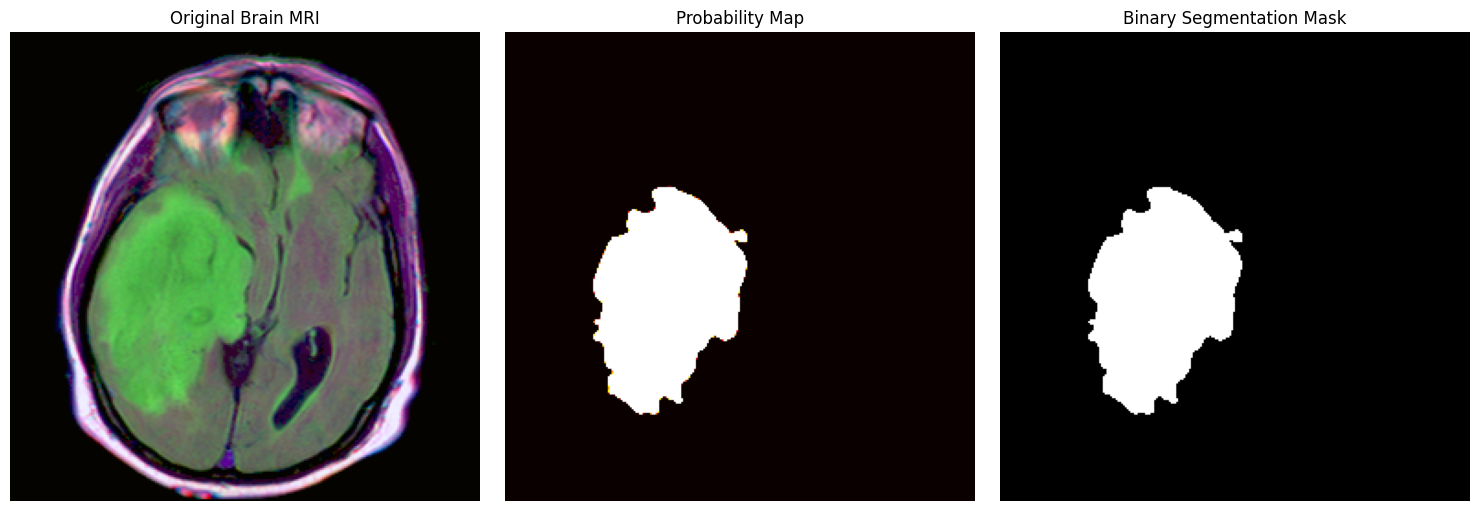

In [19]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Brain MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(probability_map, cmap="hot")
plt.title("Probability Map")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(segmentation_mask, cmap="gray")
plt.title("Binary Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

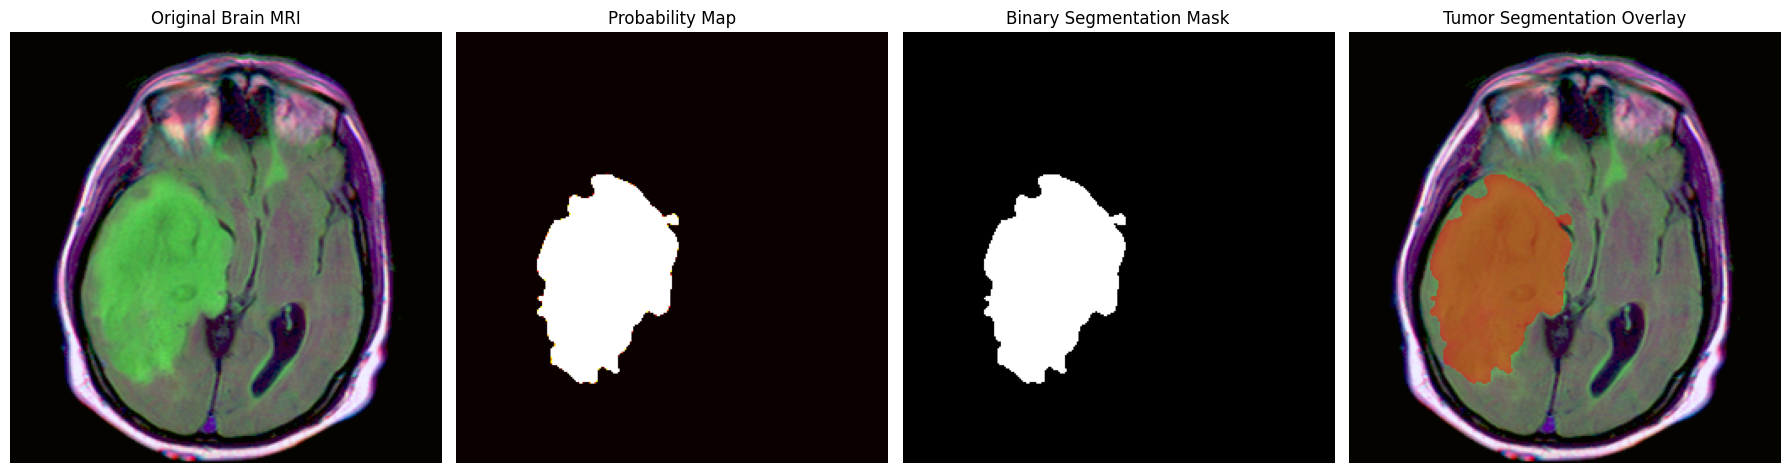

All segmentation results displayed successfully!


In [20]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Convert original MRI into RGB format
image_np = np.array(image.convert("RGB"))

# Resize mask if required
mask = Image.fromarray(
    (segmentation_mask * 255).astype(np.uint8)
)
mask = mask.resize(
    (image_np.shape[1], image_np.shape[0]),
    Image.Resampling.NEAREST
)

mask_np = np.array(mask) > 0

# Create red overlay
overlay = image_np.copy()

red = np.array([255, 0, 0])

overlay[mask_np] = (
    0.5 * image_np[mask_np] + 0.5 * red
).astype(np.uint8)

# Display all four results
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(image_np)
plt.title("Original Brain MRI")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(probability_map, cmap="hot")
plt.title("Probability Map")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(mask_np, cmap="gray")
plt.title("Binary Segmentation Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(overlay)
plt.title("Tumor Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("All segmentation results displayed successfully!")


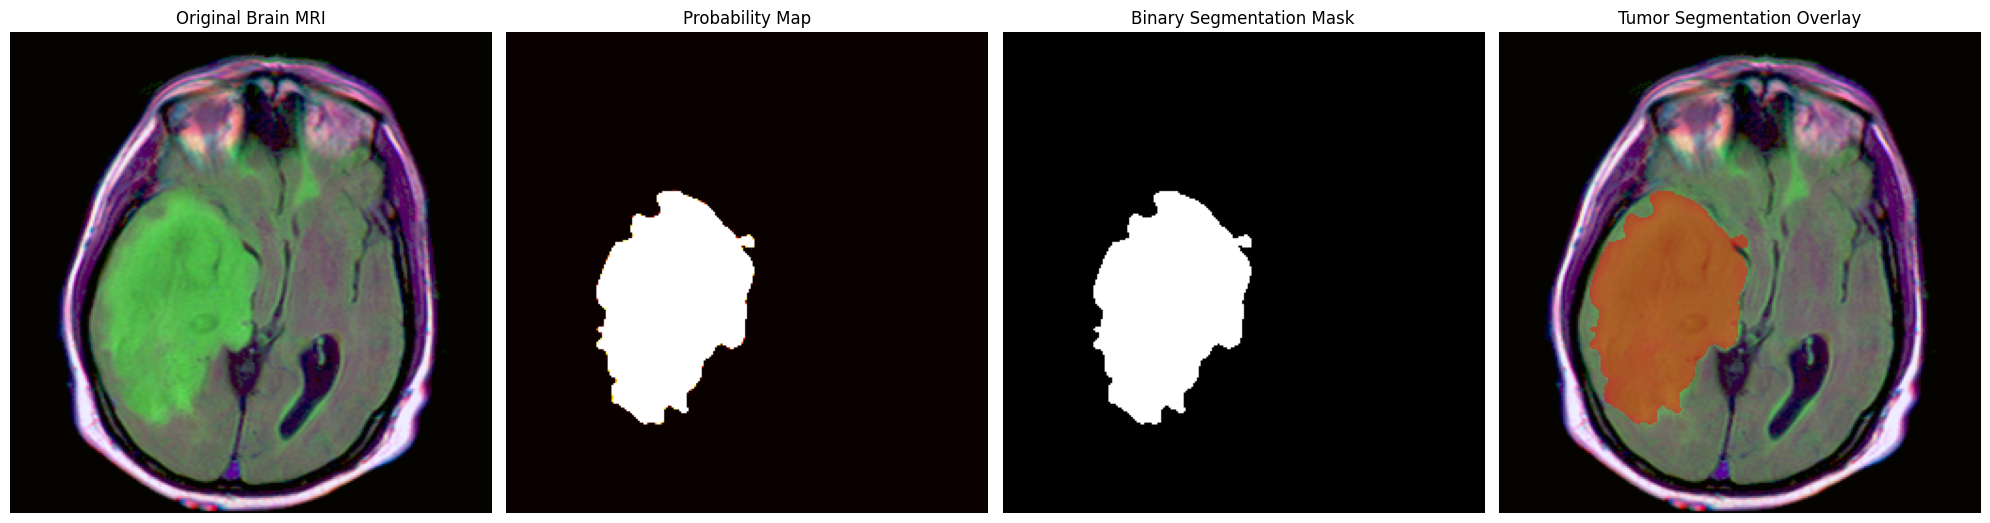

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from google.colab import files

# Prepare original MRI
image_np = np.array(image.convert("RGB"))

# Resize segmentation mask
mask_img = Image.fromarray(
    (segmentation_mask * 255).astype(np.uint8)
)
mask_img = mask_img.resize(
    (image_np.shape[1], image_np.shape[0]),
    Image.Resampling.NEAREST
)

mask_np = np.array(mask_img) > 0

# Create overlay
overlay = image_np.copy()
overlay[mask_np] = (
    0.5 * image_np[mask_np] +
    0.5 * np.array([255, 0, 0])
).astype(np.uint8)

# Create all four visualizations
fig, ax = plt.subplots(1, 4, figsize=(20, 6))

ax[0].imshow(image_np)
ax[0].set_title("Original Brain MRI")

ax[1].imshow(probability_map, cmap="hot")
ax[1].set_title("Probability Map")

ax[2].imshow(mask_np, cmap="gray")
ax[2].set_title("Binary Segmentation Mask")

ax[3].imshow(overlay)
ax[3].set_title("Tumor Segmentation Overlay")

for a in ax:
    a.axis("off")

plt.tight_layout()

# IMPORTANT: Save BEFORE displaying
fig.savefig(
    "brain_tumor_segmentation_results.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Download the saved image
files.download("brain_tumor_segmentation_results.png")


In [9]:
print("Minimum probability:", probability_map.min())
print("Maximum probability:", probability_map.max())
print("Mean probability:", probability_map.mean())
print("Pixels above 0.1:", np.sum(probability_map > 0.1))
print("Pixels above 0.3:", np.sum(probability_map > 0.3))
print("Pixels above 0.5:", np.sum(probability_map > 0.5))

Minimum probability: 7.5139674e-06
Maximum probability: 3.665747e-05
Mean probability: 2.1039345e-05
Pixels above 0.1: 0
Pixels above 0.3: 0
Pixels above 0.5: 0


In [11]:
print("Image mode:", image.mode)
print("Image size:", image.size)

img_array = np.asarray(image)

print("Image shape:", img_array.shape)

for i in range(3):
    print(
        f"Channel {i+1}:",
        "Min =", img_array[:,:,i].min(),
        "Max =", img_array[:,:,i].max(),
        "Mean =", img_array[:,:,i].mean()
    )

Image mode: RGB
Image size: (256, 256)
Image shape: (256, 256, 3)
Channel 1: Min = 4 Max = 239 Mean = 59.65196228027344
Channel 2: Min = 3 Max = 238 Mean = 66.12484741210938
Channel 3: Min = 0 Max = 255 Mean = 57.84906005859375


In [12]:
print("Output shape:", output.shape)
print("Output min:", output.min().item())
print("Output max:", output.max().item())
print("Output mean:", output.mean().item())

print("Model input min:", input_batch.min().item())
print("Model input max:", input_batch.max().item())

Output shape: torch.Size([1, 1, 256, 256])
Output min: 7.5139673754165415e-06
Output max: 3.665747135528363e-05
Output mean: 2.1039344574091956e-05
Model input min: -1.009353756904602
Model input max: -0.9484130144119263
